# BTL01 — Xấp xỉ Gaussian bằng mạng MLP

Notebook độc lập. Chọn **Restart Kernel and Run All Cells** để chạy từ đầu.
Code dùng PyTorch, ghi chú tiếng Việt và chạy trên CPU. Kết quả lưu trong `outputs/`.

## 1. Thư viện và cấu hình

Cài thư viện bằng `python -m pip install -r requirements.txt`.
Đổi `GROUP` thành `"A"`, `"B"` hoặc `"C"` để chạy riêng; giữ `"all"` để chạy đủ 24 cấu hình × 3 seed = 72 lượt.
Mỗi cấu hình dùng ba seed 11, 22, 33; Adam, batch 128 và chạy đủ 100 epoch. Chọn checkpoint tốt nhất bằng validation; kết quả báo cáo dạng trung bình ± độ lệch chuẩn.


In [1]:
import copy
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(1)
GROUP = "all"
config = {"data_seed": 2026, "model_seeds": [11, 22, 33], "batch_size": 128,
          "epochs": 100, "learning_rate": 0.003, "optimizer": "Adam",
          "activation": "Tanh", "output_activation": "Sigmoid",
          "train_size": 2000, "validation_size": 256, "test_size": 100,
          "device": "cpu", "stopping": "Chạy đủ 100 epoch"}

ROOT = Path.cwd()
if (ROOT / "BTL01" / "btl01.ipynb").exists():
    ROOT = ROOT / "BTL01"
OUT = ROOT / "outputs"
if GROUP != "all":
    OUT = OUT / f"group_{GROUP}"
for folder in ("data", "logs", "models", "figures"):
    (OUT / folder).mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")


337

## 2. Gaussian và dữ liệu

Với μ = (0, 0) và C = [[0,3; -0,5], [-0,5; 2]], ta tính:

$$f(x)=\frac{1}{2\pi\sqrt{\det(C)}}\exp\left[-\frac{1}{2}(x-\mu)^TC^{-1}(x-\mu)\right].$$

Lấy đều x1 trong [-2, 2], x2 trong [-4, 4]. Ba tập dùng seed 2026, 2027, 2028 để sinh độc lập.
Nhóm A lấy lần lượt 200–2.000 mẫu đầu từ cùng tập huấn luyện; validation và test luôn giữ nguyên.


In [2]:
MU = np.array([0.0, 0.0])
COV = np.array([[0.3, -0.5], [-0.5, 2.0]])
PEAK = float(1 / (2 * np.pi * np.sqrt(np.linalg.det(COV))))

def gaussian(x):
    delta = np.asarray(x, dtype=np.float64) - MU
    exponent = np.sum((delta @ np.linalg.inv(COV)) * delta, axis=1)
    return PEAK * np.exp(-0.5 * exponent)

def make_data(n, seed):
    rng = np.random.default_rng(seed)
    x = np.column_stack([rng.uniform(-2, 2, n), rng.uniform(-4, 4, n)])
    return x.astype(np.float32), gaussian(x).astype(np.float32)

x_train, y_train = make_data(config["train_size"], config["data_seed"])
x_val, y_val = make_data(config["validation_size"], config["data_seed"] + 1)
x_test, y_test = make_data(config["test_size"], config["data_seed"] + 2)
for name, x, y in [("train", x_train, y_train), ("validation", x_val, y_val),
                   ("test", x_test, y_test)]:
    pd.DataFrame({"x1": x[:, 0], "x2": x[:, 1], "y": y}).to_csv(
        OUT / "data" / f"{name}.csv", index=False)
display(pd.DataFrame({"x1": x_train[:, 0], "x2": x_train[:, 1], "y": y_train}).describe())

,x1,x2,y
count,2000.000000,2000.000000,2.000000e+03
mean,0.030335,-0.028755,3.135857e-02
std,1.152078,2.277785,5.815432e-02
min,-1.994342,-3.995234,8.896944e-14
25%,-0.964833,-1.912039,6.782782e-05
50%,0.044008,-0.067990,3.387829e-03
75%,1.020256,1.909852,2.813674e-02
max,1.999133,3.999651,2.686690e-01


## 3. Khảo sát dữ liệu

Hình 3D thể hiện mẫu và hàm thật. Các biểu đồ tần số cho thấy x1, x2 lấy đều nhưng phần lớn y gần 0 vì nhiều điểm nằm xa đỉnh Gaussian.

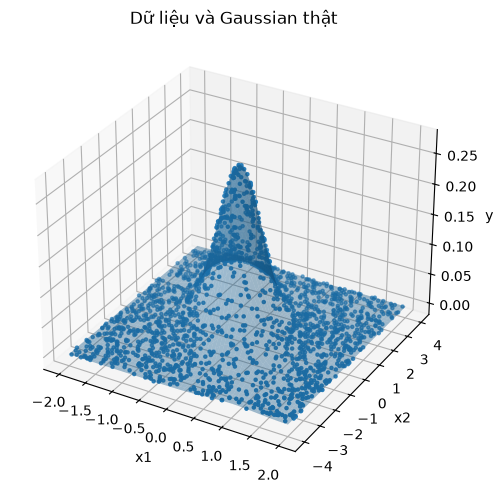

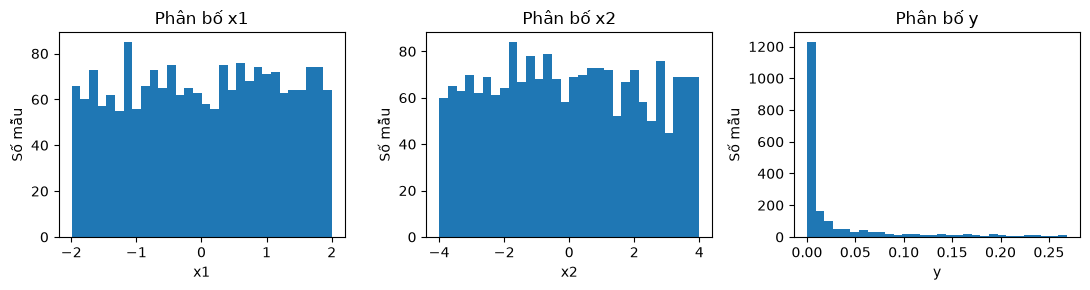

In [3]:
def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / name, dpi=160)
    plt.show()
    plt.close()

# Dùng chung lưới này để vẽ hàm thật và mô hình dự đoán.
xx, yy = np.meshgrid(np.linspace(-2, 2, 50), np.linspace(-4, 4, 50))
grid = np.column_stack([xx.ravel(), yy.ravel()]).astype(np.float32)
truth = gaussian(grid).reshape(xx.shape)
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x_train[:, 0], x_train[:, 1], y_train, s=5)
ax.plot_surface(xx, yy, truth, alpha=0.4)
ax.set(xlabel="x1", ylabel="x2", zlabel="y", title="Dữ liệu và Gaussian thật")
save_plot("data_and_function.png")

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, values, label in zip(axes, [x_train[:, 0], x_train[:, 1], y_train], ["x1", "x2", "y"]):
    ax.hist(values, bins=30)
    ax.set(xlabel=label, ylabel="Số mẫu", title=f"Phân bố {label}")
save_plot("target_distribution.png")

## 4. Mô hình MLP

Kiến trúc: **2 đầu vào → [Linear + Tanh] × số tầng ẩn → Linear + Sigmoid → 1 đầu ra**.
`width` là số neuron mỗi tầng, `depth` là số tầng ẩn.
Chia đầu vào cho [2, 4] để đưa về [-1, 1]. Nhân đầu ra Sigmoid với mật độ cực đại để đưa về thang đo Gaussian.

In [4]:
class MLP(nn.Module):
    def __init__(self, width, depth):
        super().__init__()
        layers = []
        inputs = 2
        for _ in range(depth):
            layers.extend([nn.Linear(inputs, width), nn.Tanh()])
            inputs = width
        layers.extend([nn.Linear(inputs, 1), nn.Sigmoid()])
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x / x.new_tensor([2.0, 4.0])) * PEAK

def predict(model, x):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(x)).numpy().ravel()

def load_model(name):
    saved = torch.load(OUT / "models" / f"{name}.pt", weights_only=True)
    model = MLP(saved["width"], saved["depth"])
    model.load_state_dict(saved["state_dict"])
    return model

def mse(y, prediction):
    return float(np.mean((y - prediction) ** 2))

### Sơ đồ kiến trúc

Hình dưới được vẽ trực tiếp trong notebook và lưu vào `outputs/figures/architecture.png`; báo cáo dùng lại đúng hình này.


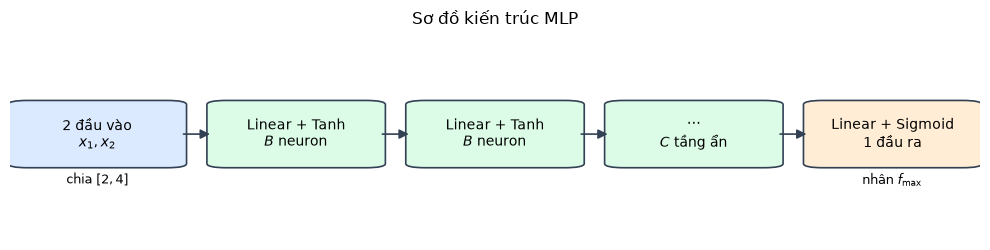

In [10]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
boxes = [
    (0.01, "2 đầu vào\n$x_1, x_2$", "#dbeafe"),
    (0.215, "Linear + Tanh\n$B$ neuron", "#dcfce7"),
    (0.42, "Linear + Tanh\n$B$ neuron", "#dcfce7"),
    (0.625, "$\\cdots$\n$C$ tầng ẩn", "#dcfce7"),
    (0.83, "Linear + Sigmoid\n1 đầu ra", "#ffedd5"),
]
box_width, box_height = 0.16, 0.30
for x, label, color in boxes:
    ax.add_patch(FancyBboxPatch((x, 0.36), box_width, box_height,
                                boxstyle="round,pad=0.012,rounding_size=0.02",
                                linewidth=1.2, edgecolor="#334155", facecolor=color))
    ax.text(x + box_width / 2, 0.36 + box_height / 2, label,
            ha="center", va="center", fontsize=10)
for left, right in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((left[0] + box_width + 0.006, 0.51),
                                 (right[0] - 0.006, 0.51),
                                 arrowstyle="-|>", mutation_scale=14,
                                 linewidth=1.2, color="#334155"))
ax.text(0.09, 0.27, "chia $[2,4]$", ha="center", fontsize=9)
ax.text(0.91, 0.27, "nhân $f_{\\max}$", ha="center", fontsize=9)
ax.set_title("Sơ đồ kiến trúc MLP", fontsize=12)
save_plot("architecture.png")


## 5. Huấn luyện một cấu hình

`train_model` lấy n mẫu đầu của tập huấn luyện, dùng DataLoader và tự thực hiện forward → loss → backward → cập nhật trọng số. Mỗi cấu hình được chạy với ba seed 11, 22, 33.
Loss tối ưu là MSE của mật độ chia cho `PEAK`; nhân lại `PEAK²` khi ghi log để báo cáo đúng thang đo gốc.
Mỗi epoch kiểm tra validation và giữ bản sao trọng số tốt nhất. Chạy cố định 100 epoch, không dừng sớm.
Train loss theo epoch là trung bình minibatch trong quá trình cập nhật; train MSE cuối được tính lại bằng mô hình đã chọn.


In [5]:
def train_model(n, width, depth, seed, name):
    torch.manual_seed(seed)
    model = MLP(width, depth)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    loss_fn = nn.MSELoss()
    dataset = TensorDataset(torch.from_numpy(x_train[:n]), torch.from_numpy(y_train[:n, None]))
    generator = torch.Generator().manual_seed(seed + 1000)
    loader = DataLoader(dataset, batch_size=config["batch_size"], shuffle=True, generator=generator)
    vx, vy = torch.from_numpy(x_val), torch.from_numpy(y_val[:, None])
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    history = []
    start = time.perf_counter()

    for epoch in range(1, config["epochs"] + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb) / PEAK, yb / PEAK)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(vx) / PEAK, vy / PEAK).item() * PEAK ** 2
        history.append([epoch, total_loss / n * PEAK ** 2, val_loss])
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())

    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    torch.save({"state_dict": best_state, "width": width, "depth": depth,
                "seed": seed, "best_epoch": best_epoch, "validation_mse": best_loss,
                "config": config}, OUT / "models" / f"{name}.pt")
    pd.DataFrame(history, columns=["epoch", "train_mse", "validation_mse"]).to_csv(
        OUT / "logs" / f"{name}.csv", index=False)
    return {"run_id": name, "n_train": n, "width": width, "depth": depth,
            "seed": seed, "epochs": config["epochs"], "best_epoch": best_epoch,
            "train_mse": mse(y_train[:n], predict(model, x_train[:n])),
            "validation_mse": best_loss, "train_seconds": seconds}


## 6. Chạy A/B/C với ba seed

| Nhóm | Thay đổi | Giữ cố định |
|---|---|---|
| A | 200–2.000 mẫu, bước 200 | 1 tầng ẩn, 10 neuron |
| B | 1–10 neuron | 1 tầng ẩn, 2.000 mẫu |
| C | 1–4 tầng ẩn | 10 neuron/tầng, 2.000 mẫu |

Mỗi cấu hình chạy với seed 11, 22, 33. Các cấu hình dùng chung validation/test và cách huấn luyện; chưa đánh giá test ở bước này.
Cấu hình cuối được chốt theo validation MSE trung bình ba seed; bên trong cấu hình đó chọn checkpoint có validation MSE thấp nhất.


In [6]:
experiments = [("A", n, 10, 1) for n in range(200, 2001, 200)]
experiments += [("B", 2000, width, 1) for width in range(1, 11)]
experiments += [("C", 2000, 10, depth) for depth in range(1, 5)]
rows = []
for group, n, width, depth in experiments:
    if GROUP != "all" and GROUP != group:
        continue
    for seed in config["model_seeds"]:
        name = f"{group}_n{n}_w{width}_d{depth}_seed{seed}"
        print(f"Đang chạy {name}", flush=True)
        row = train_model(n, width, depth, seed, name)
        row["group"] = group
        rows.append(row)

runs = pd.DataFrame(rows)
runs.to_csv(OUT / "summary_runs.csv", index=False)
summary = runs.groupby(["group", "n_train", "width", "depth"], as_index=False).agg(
    seeds=("seed", "count"),
    train_mse_mean=("train_mse", "mean"), train_mse_std=("train_mse", "std"),
    validation_mse_mean=("validation_mse", "mean"),
    validation_mse_std=("validation_mse", "std"),
    train_seconds_mean=("train_seconds", "mean"),
    train_seconds_std=("train_seconds", "std"))
# Chốt cấu hình bằng validation trước khi xem kết quả test.
best_config_index = summary.validation_mse_mean.idxmin()
best_config = summary.loc[best_config_index]
best_runs = runs[(runs.group == best_config.group) &
                 (runs.n_train == best_config.n_train) &
                 (runs.width == best_config.width) &
                 (runs.depth == best_config.depth)].sort_values("validation_mse")
best_run_index = best_runs.index[0]
print("Cấu hình chọn theo validation trung bình:", best_config[["group", "n_train", "width", "depth"]].to_dict())
print("Checkpoint chọn theo validation:", runs.loc[best_run_index, "run_id"])


Đang chạy A_n200_w10_d1_seed11


Đang chạy A_n200_w10_d1_seed22


Đang chạy A_n200_w10_d1_seed33


Đang chạy A_n400_w10_d1_seed11


Đang chạy A_n400_w10_d1_seed22


Đang chạy A_n400_w10_d1_seed33


... (63 outputs left out)

Đang chạy C_n2000_w10_d4_seed11


Đang chạy C_n2000_w10_d4_seed22


Đang chạy C_n2000_w10_d4_seed33


Cấu hình chọn theo validation trung bình: {'group': 'C', 'n_train': 2000, 'width': 10, 'depth': 4}
Checkpoint chọn theo validation: C_n2000_w10_d4_seed22


## 7. Đánh giá trên 100 mẫu test độc lập

Sau khi chốt cấu hình bằng validation, tính MSE, MAE và RMSE test cho từng lần chạy để lập bảng A/B/C dạng trung bình ± độ lệch chuẩn qua ba seed.
Lưu toàn bộ checkpoint, log, cấu hình và dự đoán để kiểm chứng kết quả. Không dùng test để chọn lại mô hình.


In [7]:
for index, row in runs.iterrows():
    prediction = predict(load_model(row.run_id), x_test)
    runs.loc[index, "test_mse"] = mse(y_test, prediction)
    runs.loc[index, "test_mae"] = float(np.mean(np.abs(y_test - prediction)))
runs["test_rmse"] = np.sqrt(runs.test_mse)
runs.to_csv(OUT / "summary_runs.csv", index=False)

summary = runs.groupby(["group", "n_train", "width", "depth"], as_index=False).agg(
    seeds=("seed", "count"),
    train_mse_mean=("train_mse", "mean"), train_mse_std=("train_mse", "std"),
    validation_mse_mean=("validation_mse", "mean"),
    validation_mse_std=("validation_mse", "std"),
    test_mse_mean=("test_mse", "mean"), test_mse_std=("test_mse", "std"),
    test_mae_mean=("test_mae", "mean"), test_mae_std=("test_mae", "std"),
    test_rmse_mean=("test_rmse", "mean"), test_rmse_std=("test_rmse", "std"),
    train_seconds_mean=("train_seconds", "mean"),
    train_seconds_std=("train_seconds", "std"))
summary.to_csv(OUT / "summary_abc.csv", index=False)
display(summary)

selected = runs.loc[best_run_index].to_dict()
selected["selected_by"] = "Validation MSE trung bình thấp nhất qua ba seed; checkpoint có validation MSE thấp nhất trong cấu hình"
selected["config_validation_mse_mean"] = float(best_config.validation_mse_mean)
selected["config_validation_mse_std"] = float(best_config.validation_mse_std)
selected["checkpoint"] = f"models/{selected['run_id']}.pt"
(OUT / "selected_model.json").write_text(
    json.dumps(selected, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
best_model = load_model(selected["run_id"])
prediction = predict(best_model, x_test)
pd.DataFrame({"x1": x_test[:, 0], "x2": x_test[:, 1], "y_true": y_test,
              "y_pred": prediction}).to_csv(OUT / "test_predictions.csv", index=False)
print(json.dumps(selected, ensure_ascii=False, indent=2, default=str))


,group,n_train,width,depth,seeds,train_mse_mean,train_mse_std,validation_mse_mean,validation_mse_std,test_mse_mean,test_mse_std,test_mae_mean,test_mae_std,test_rmse_mean,test_rmse_std,train_seconds_mean,train_seconds_std
0,A,200,10,1,3,0.003504,2.047550e-05,0.002914,4.256477e-05,0.002523,4.696993e-05,0.041047,0.000893,0.050225,0.000466,1.019600,0.937792
1,A,400,10,1,3,0.003358,4.420203e-06,0.002765,3.158554e-06,0.002377,1.360070e-06,0.036489,0.000326,0.048752,0.000014,0.894588,0.035749
2,A,600,10,1,3,0.003157,3.263150e-06,0.002745,2.759207e-06,0.002359,2.001296e-06,0.035765,0.000027,0.048569,0.000021,1.190742,0.037913
3,A,800,10,1,3,0.003476,8.047778e-06,0.002759,3.245920e-06,0.002375,4.388116e-06,0.036828,0.000100,0.048730,0.000045,1.653730,0.053898
4,A,1000,10,1,3,0.003372,1.079157e-05,0.002750,7.177185e-06,0.002367,6.641443e-06,0.036530,0.000041,0.048655,0.000068,1.721351,0.331733
5,A,1200,10,1,3,0.003343,2.555692e-05,0.002738,1.678726e-05,0.002357,1.695688e-05,0.036622,0.000178,0.048553,0.000175,2.251692,0.080488
6,A,1400,10,1,3,0.003326,4.688905e-05,0.002728,3.208925e-05,0.002344,3.404022e-05,0.036786,0.000113,0.048411,0.000352,2.412937,0.165692
7,A,1600,10,1,3,0.003160,1.333254e-04,0.002652,1.016645e-04,0.002263,1.058371e-04,0.036303,0.000405,0.047558,0.001116,2.915152,0.125370
8,A,1800,10,1,3,0.002941,3.970137e-04,0.002427,2.942838e-04,0.002039,2.889115e-04,0.035483,0.000873,0.045081,0.003220,3.167298,0.290246
9,A,2000,10,1,3,0.002486,6.472431e-04,0.002057,5.144879e-04,0.001707,4.372838e-04,0.033282,0.003092,0.041076,0.005389,3.598763,0.098116


{
  "run_id": "C_n2000_w10_d4_seed22",
  "n_train": 2000,
  "width": 10,
  "depth": 4,
  "seed": 22,
  "epochs": 100,
  "best_epoch": 100,
  "train_mse": 4.427738531376235e-05,
  "validation_mse": 3.247369294508913e-05,
  "train_seconds": 7.368968099995982,
  "group": "C",
  "test_mse": 3.26943481923081e-05,
  "test_mae": 0.004428439773619175,
  "test_rmse": 0.005717897182733186,
  "selected_by": "Validation MSE trung bình thấp nhất qua ba seed; checkpoint có validation MSE thấp nhất trong cấu hình",
  "config_validation_mse_mean": 0.0009394040140206867,
  "config_validation_mse_std": 0.0015639830914516385,
  "checkpoint": "models/C_n2000_w10_d4_seed22.pt"
}


## 8. Biểu đồ so sánh

Vẽ riêng mỗi nhóm để cả chế độ chạy đầy đủ và chạy một nhóm đều có hình phù hợp.
Điểm là trung bình ba seed, thanh sai số là ±1 độ lệch chuẩn. Train/validation cùng cao gợi ý thiếu khớp hoặc tối ưu chưa tốt. Train thấp nhưng validation cao có thể gợi ý quá khớp.
Không kết luận mạng rộng/sâu luôn tốt hơn chỉ từ ba seed.


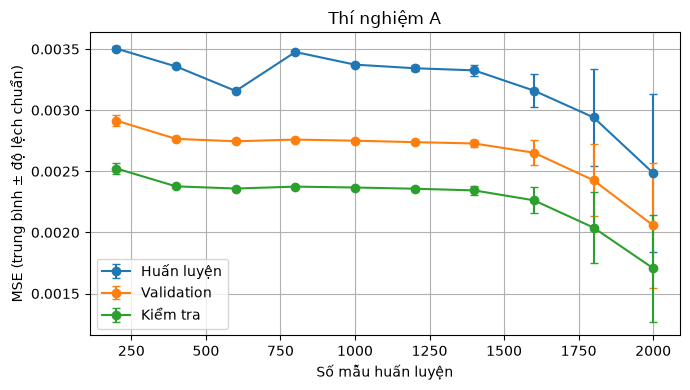

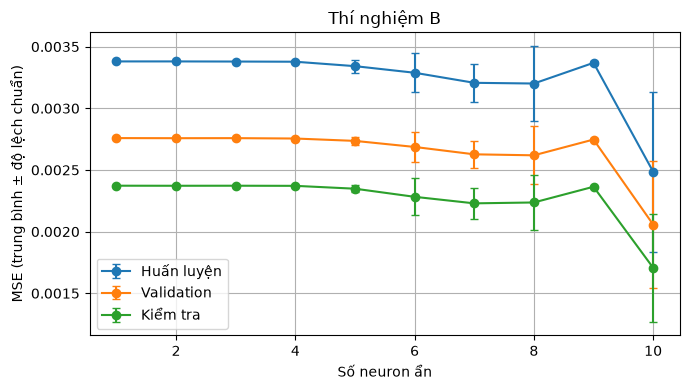

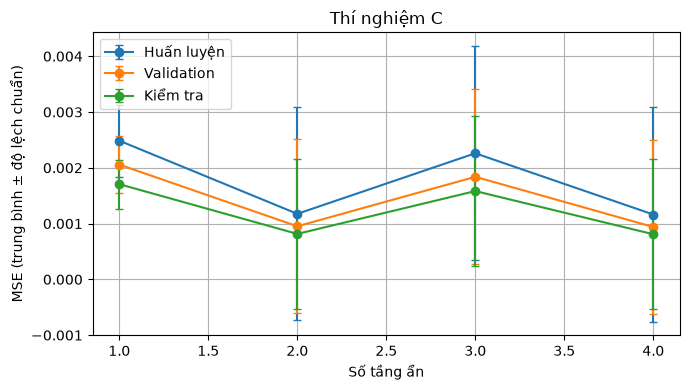

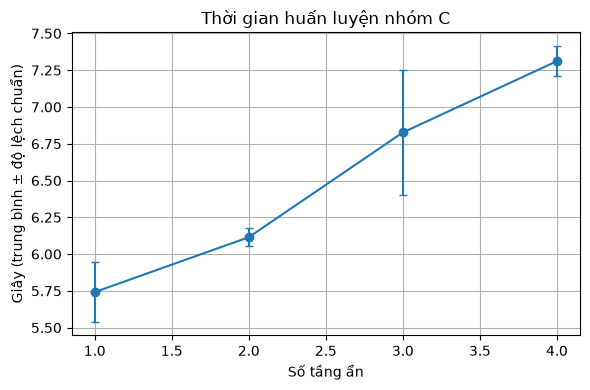

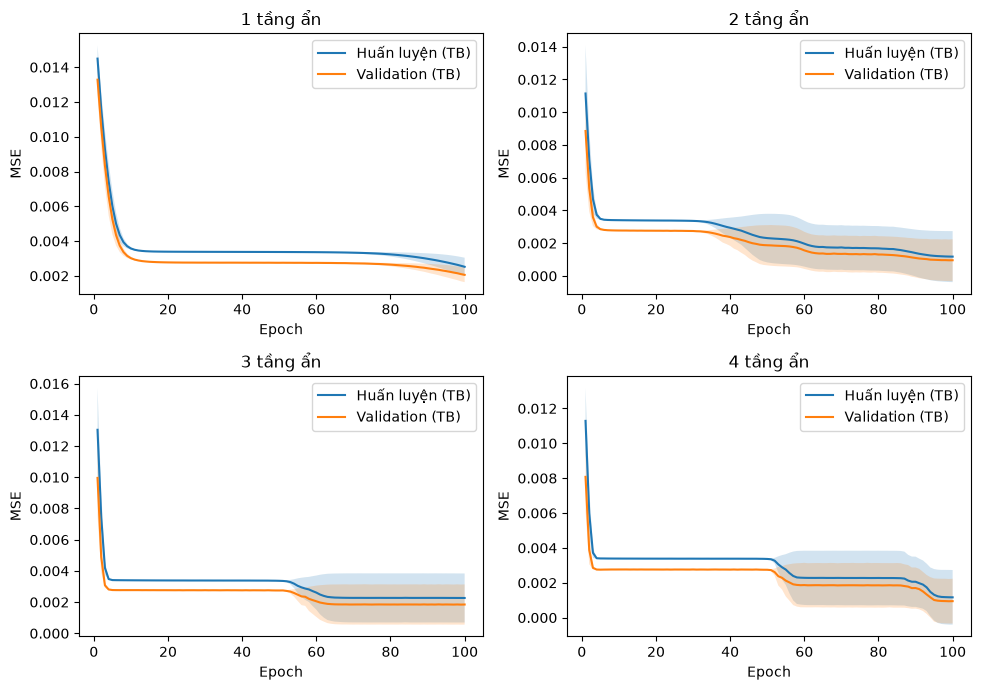

In [8]:
for group, column, label in [("A", "n_train", "Số mẫu huấn luyện"),
                              ("B", "width", "Số neuron ẩn"), ("C", "depth", "Số tầng ẩn")]:
    part = summary[summary.group == group]
    if part.empty:
        continue
    plt.figure(figsize=(7, 4))
    for mean_col, std_col, legend in [
            ("train_mse_mean", "train_mse_std", "Huấn luyện"),
            ("validation_mse_mean", "validation_mse_std", "Validation"),
            ("test_mse_mean", "test_mse_std", "Kiểm tra")]:
        plt.errorbar(part[column], part[mean_col], yerr=part[std_col],
                     fmt="o-", capsize=3, label=legend)
    plt.xlabel(label)
    plt.ylabel("MSE (trung bình ± độ lệch chuẩn)")
    plt.title(f"Thí nghiệm {group}")
    plt.legend()
    plt.grid(True)
    save_plot(f"{group}_mse.png")

depth_results = summary[summary.group == "C"]
if not depth_results.empty:
    plt.figure(figsize=(6, 4))
    plt.errorbar(depth_results.depth, depth_results.train_seconds_mean,
                 yerr=depth_results.train_seconds_std, fmt="o-", capsize=3)
    plt.xlabel("Số tầng ẩn")
    plt.ylabel("Giây (trung bình ± độ lệch chuẩn)")
    plt.title("Thời gian huấn luyện nhóm C")
    plt.grid(True)
    save_plot("depth_time.png")

    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for ax, depth in zip(axes.ravel(), sorted(depth_results.depth.unique())):
        part = runs[(runs.group == "C") & (runs.depth == depth)]
        histories = [pd.read_csv(OUT / "logs" / f"{row.run_id}.csv") for row in part.itertuples()]
        epochs = histories[0].epoch.to_numpy()
        train = np.vstack([h.train_mse.to_numpy() for h in histories])
        val = np.vstack([h.validation_mse.to_numpy() for h in histories])
        ax.plot(epochs, train.mean(0), label="Huấn luyện (TB)")
        ax.fill_between(epochs, train.mean(0) - train.std(0), train.mean(0) + train.std(0), alpha=0.2)
        ax.plot(epochs, val.mean(0), label="Validation (TB)")
        ax.fill_between(epochs, val.mean(0) - val.std(0), val.mean(0) + val.std(0), alpha=0.2)
        ax.set(xlabel="Epoch", ylabel="MSE", title=f"{depth} tầng ẩn")
        ax.legend()
    save_plot("depth_convergence.png")


## 9. Kiểm tra mô hình được chọn

Điểm gần đường chéo thể hiện dự đoán gần nhãn thật. Hai bề mặt dùng cùng giới hạn trục đứng để dễ so sánh.


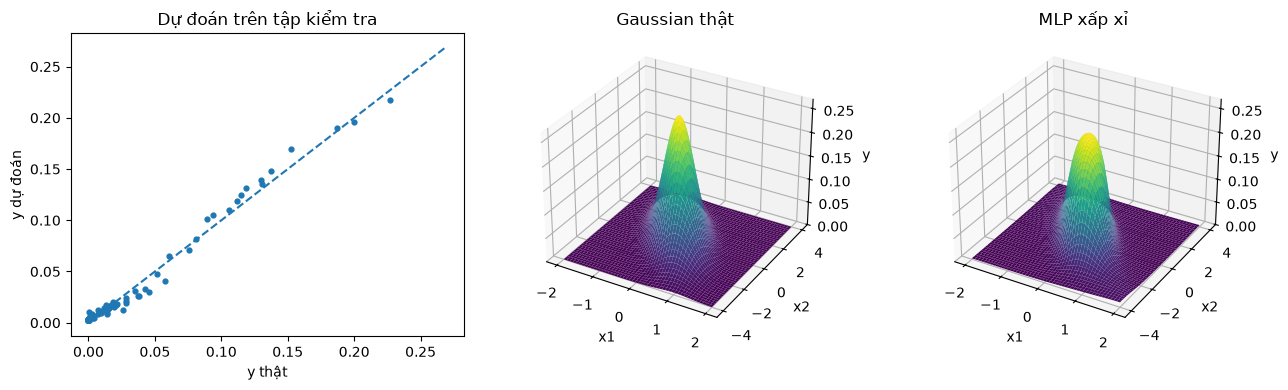

In [9]:
fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(131)
ax.scatter(y_test, prediction, s=12)
ax.plot([0, PEAK], [0, PEAK], "--")
ax.set(xlabel="y thật", ylabel="y dự đoán", title="Dự đoán trên tập kiểm tra")
approximation = predict(best_model, grid).reshape(xx.shape)
for position, surface, title in [(2, truth, "Gaussian thật"), (3, approximation, "MLP xấp xỉ")]:
    ax = fig.add_subplot(1, 3, position, projection="3d")
    ax.plot_surface(xx, yy, surface, cmap="viridis")
    ax.set(xlabel="x1", ylabel="x2", zlabel="y", zlim=(0, PEAK), title=title)
save_plot("selected_model.png")

## 10. Nhận xét và giới hạn

- **Nhóm A — số mẫu:** Test MSE trung bình giảm từ 0,002523 (200 mẫu) xuống 0,001707 (2.000 mẫu), khoảng 32%. Từ 400 đến 1.400 mẫu sai số gần như bão hòa quanh 0,00234–0,00238; cải thiện rõ nhất ở 1.600–2.000 mẫu. Độ lệch chuẩn tăng ở các mức cuối, cho thấy ba seed chưa đủ để kết luận chắc chắn.
- **Nhóm B — độ rộng:** Width 1–4 gần như không đổi (test MSE ≈ 0,00237); width 6–8 giảm còn 0,00223–0,00228; width 10 đạt 0,001707, còn width 9 tăng lại 0,002364. Train và validation sát nhau ở mọi width, nên chưa thấy quá khớp rõ; width nhỏ chủ yếu thiếu khớp.
- **Nhóm C — độ sâu:** Depth 1 có test MSE 0,001707. Depth 2, 3, 4 có trung bình lần lượt 0,000815; 0,001583; 0,000809 nhưng độ lệch chuẩn rất lớn (≈0,00134). Ở mỗi cấu hình sâu đều có một seed không hội tụ (test MSE ≈ 0,00236), nên kết quả phụ thuộc mạnh vào khởi tạo; không thể kết luận “càng sâu càng tốt”.
- **Thời gian:** Thời gian trung bình tăng theo độ sâu: 5,74 s (1 tầng) → 6,11 s (2) → 6,83 s (3) → 7,31 s (4) trên CPU. Chênh lệch này chỉ mang tính tham khảo vì đo một lần cho mỗi seed.
- **Mô hình cuối:** Chọn theo validation trung bình được C, n=2.000, width=10, depth=4; checkpoint seed 22 có validation MSE 3,25e-05, test MSE 3,27e-05, MAE 0,00443, RMSE 0,00572. Tuy nhiên khoảng cách với depth=2 rất nhỏ so với độ lệch chuẩn, nên lựa chọn này không đủ mạnh để khẳng định depth=4 tốt hơn.
- **Giới hạn:** Chỉ 3 seed, test 100 mẫu, một bộ siêu tham số; các seed “xấu” cho thấy cần thêm seed hoặc điều chỉnh khởi tạo/optimizer để đánh giá độ sâu ổn định hơn.
